# Óxidos básicos e óxidos ácidos (anidridos)
### Funções inorgânicas — óxidos

**Objetivo:** Escrever as reações dos óxidos com água, ácido e base e relacionar o óxido ao ácido correspondente pelo número de oxidação.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Os **óxidos básicos** são, em geral, óxidos de metais. Com água formam hidróxido; com ácido formam sal + água:

$$
\boxed{\mathrm{M_xO_y + y\,H_2O \rightarrow x\,M(OH)_{2y/x}}}
$$
$$
\mathrm{CaO + 2HCl \rightarrow CaCl_2 + H_2O}
$$

Os **óxidos ácidos** (anidridos) são óxidos de ametais. Com água formam ácido; com base formam sal + água:

$$
\boxed{\mathrm{N_2O_5 + H_2O \rightarrow 2HNO_3}}
$$
$$
\mathrm{CO_2 + 2NaOH \rightarrow Na_2CO_3 + H_2O}
$$

A relação entre o óxido e o ácido correspondente é o **número de oxidação do ametal**, que se conserva na transformação:

$$
\mathrm{SO_2}\ (\mathrm{S} = +4) \rightarrow \mathrm{H_2SO_3}\ (\mathrm{S} = +4)
\qquad
\mathrm{SO_3}\ (\mathrm{S} = +6) \rightarrow \mathrm{H_2SO_4}\ (\mathrm{S} = +6)
$$

Ou seja: o mesmo elemento, com NOx diferentes, gera ácidos diferentes — e o de NOx maior é o mais forte.

## 2. Exemplo resolvido passo a passo

**Chuva ácida:** o $\mathrm{SO_2}$ da queima de combustível é oxidado a $\mathrm{SO_3}$ na atmosfera e depois hidratado. Calcule a massa de $\mathrm{H_2SO_4}$ formada a partir de $64\ \mathrm{g}$ de $\mathrm{SO_2}$ (100% de conversão).

**Passo 1 — mols de $\mathrm{SO_2}$ ($M = 32{,}06 + 2\cdot16{,}00 = 64{,}06$).**

$$
n = \frac{64}{64{,}06} \approx 1{,}00\ \mathrm{mol}
$$

**Passo 2 — estequiometria.**

$$
\mathrm{SO_2 + \tfrac12 O_2 \rightarrow SO_3}
\qquad
\mathrm{SO_3 + H_2O \rightarrow H_2SO_4}
$$

Como 1 mol de S vira 1 mol de ácido:

$$
n_{\mathrm{H_2SO_4}} = 1{,}00\ \mathrm{mol}
$$

**Passo 3 — massa ($M = 98{,}08$).**

$$
m = 1{,}00 \cdot 98{,}08 = \boxed{98{,}1\ \mathrm{g}}
$$

**Passo 4 — e o pH?** Dissolvido em 1 L de água da chuva (considerando diluição desprezível), a concentração seria $\approx1\ \mathrm{mol/L}$. Mesmo com só 1% de conversão, já daria pH próximo de 2 — daí a acidez das chuvas em regiões industriais.

## 3. Conferindo o cálculo com Python

In [2]:
# @title SO2 -> H2SO4
from rdkit import Chem
from rdkit.Chem import Descriptors
import math

M_SO2 = Descriptors.MolWt(Chem.MolFromSmiles("O=S=O"))
M_SO3 = Descriptors.MolWt(Chem.MolFromSmiles("O=S(=O)=O"))
M_H2SO4 = Descriptors.MolWt(Chem.MolFromSmiles("OS(=O)(=O)O"))

massa_so2 = 64.0
n_so2 = massa_so2 / M_SO2
massa_acido = n_so2 * M_H2SO4

print(f"M(SO2)   = {M_SO2:.2f} g/mol")
print(f"M(SO3)   = {M_SO3:.2f} g/mol")
print(f"M(H2SO4) = {M_H2SO4:.2f} g/mol")
print(f"n(SO2)   = {n_so2:.3f} mol")
print(f"massa de H2SO4 formada = {massa_acido:.1f} g")
print(f"massa de água consumida = {n_so2 * 18.02:.1f} g")
print(f"pH se dissolvido em 1 L (ácido forte 1 mol/L) = {-math.log10(n_so2):.2f}")

M(SO2)   = 64.06 g/mol
M(SO3)   = 80.06 g/mol
M(H2SO4) = 98.08 g/mol
n(SO2)   = 0.999 mol
massa de H2SO4 formada = 98.0 g
massa de água consumida = 18.0 g
pH se dissolvido em 1 L (ácido forte 1 mol/L) = 0.00


## 4. Visualização

### 4.1 Trióxido de enxofre em 3D — arraste para girar

O $\mathrm{SO_3}$ é trigonal plano (120°) e é o anidrido do ácido sulfúrico. Gire a figura para confirmar que os três oxigênios estão no mesmo plano do enxofre.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("O=S(=O)=O")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Pentóxido de dinitrogênio em 3D

O $\mathrm{N_2O_5}$ é o anidrido nítrico: com água forma $\mathrm{HNO_3}$. É um sólido branco que sublima; a estrutura tem os dois nitrogênios ligados por um oxigênio em ponte.

In [4]:
molecula_3d("O=[N+]([O-])O[N+](=O)[O-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

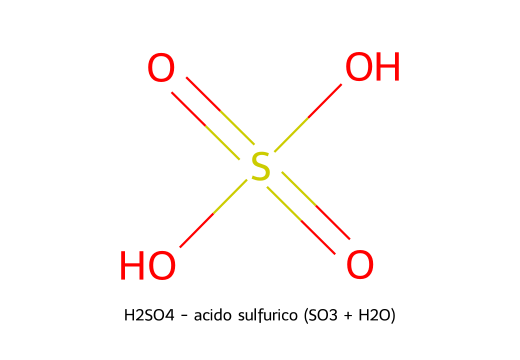

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("O=S(=O)O", legenda="H2SO3 - acido sulfuroso (SO2 + H2O)")
estrutura_2d("OS(=O)(=O)O", legenda="H2SO4 - acido sulfurico (SO3 + H2O)")

### 4.4 Galeria: óxido → ácido correspondente

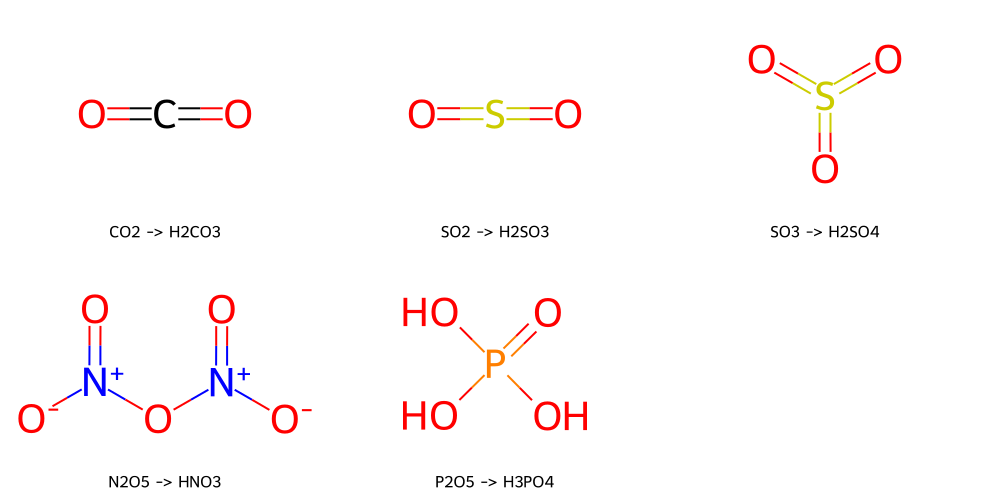

In [6]:
# @title Anidridos e seus ácidos
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

pares = [
    ("CO2 -> H2CO3", "O=C=O"),
    ("SO2 -> H2SO3", "O=S=O"),
    ("SO3 -> H2SO4", "O=S(=O)=O"),
    ("N2O5 -> HNO3", "O=[N+]([O-])O[N+](=O)[O-]"),
    ("P2O5 -> H3PO4", "OP(=O)(O)O"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in pares],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in pares], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 Neutralização do CO₂ pela cal — o teste clássico

A água de cal fica **leitosa** ao receber $\mathrm{CO_2}$, porque precipita $\mathrm{CaCO_3}$:

$$
\mathrm{Ca(OH)_2 + CO_2 \rightarrow CaCO_3\downarrow + H_2O}
$$

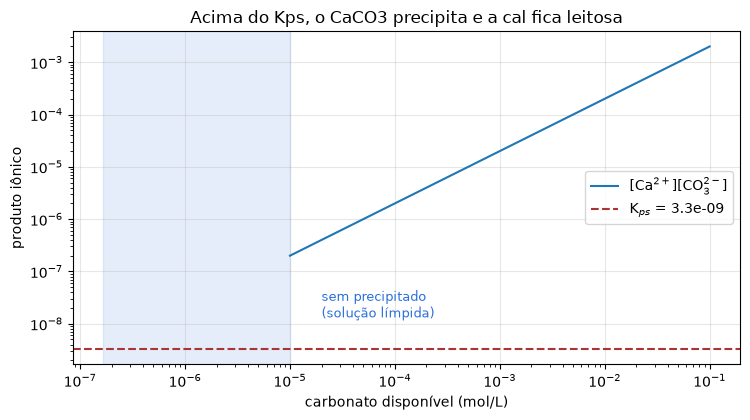

In [7]:
# @title Precipitação de CaCO3
import numpy as np
import matplotlib.pyplot as plt

KPS_CACO3 = 3.3e-9
concentracoes_co2 = np.logspace(-5, -1, 100)     # mol/L dissolvido
# Ca(OH)2 saturada ~ 0,02 mol/L -> [Ca2+] = 0,02
CA = 0.02
produto = CA * concentracoes_co2

plt.figure(figsize=(7.6, 4.3))
plt.plot(concentracoes_co2, produto, label="[Ca$^{2+}$][CO$_3^{2-}$]")
plt.axhline(KPS_CACO3, color="#a33", linestyle="--", label=f"K$_{{ps}}$ = {KPS_CACO3:.1e}")
plt.axvspan(1e-5, KPS_CACO3 / CA, color="#2a6fdb", alpha=0.12)
plt.text(2e-5, KPS_CACO3 * 4, "sem precipitado\n(solução límpida)", fontsize=9, color="#2a6fdb")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("carbonato disponível (mol/L)")
plt.ylabel("produto iônico")
plt.title("Acima do Kps, o CaCO3 precipita e a cal fica leitosa")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 4.6 pH de uma solução de óxido básico

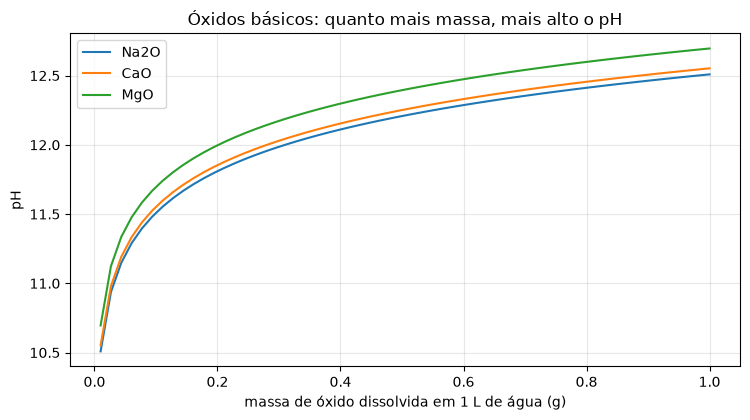

In [8]:
# @title pH x quantidade de óxido dissolvido
import math

oxidos = [("Na2O", 61.98, 2), ("CaO", 56.08, 2), ("MgO", 40.30, 2)]
massas = np.linspace(0.01, 1.0, 60)      # g em 1 L de água

plt.figure(figsize=(7.6, 4.3))
for nome, massa_molar, oh_por_mol in oxidos:
    molaridade = massas / massa_molar
    oh = np.clip(molaridade * oh_por_mol, 1e-14, 1)
    plt.plot(massas, 14 + np.log10(oh), label=nome)
plt.xlabel("massa de óxido dissolvida em 1 L de água (g)")
plt.ylabel("pH")
plt.title("Óxidos básicos: quanto mais massa, mais alto o pH")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- O número de oxidação do ametal é a "impressão digital" do par óxido/ácido: ele não muda na hidratação.
- O mesmo elemento pode gerar dois ácidos: $\mathrm{SO_2}\rightarrow\mathrm{H_2SO_3}$ (fraco) e $\mathrm{SO_3}\rightarrow\mathrm{H_2SO_4}$ (forte).
- Óxido básico + água aumenta o pH; óxido ácido + água diminui. O gráfico do pH resume isso.
- O teste da água de cal é qualitativo mas muito sensível: precipita com teores baixíssimos de $\mathrm{CO_2}$.

## 6. Exercício de fixação

$4{,}4\ \mathrm{g}$ de $\mathrm{CO_2}$ foram borbulhados em $\mathrm{NaOH}$ $0{,}100\ \mathrm{mol/L}$. Que volume de base é necessário para neutralizar todo o gás formando carbonato de sódio?

In [9]:
# @title Exercício
M_CO2 = Descriptors.MolWt(Chem.MolFromSmiles("O=C=O"))
massa_co2 = 4.4
n_co2 = massa_co2 / M_CO2
# CO2 + 2 NaOH -> Na2CO3 + H2O
n_naoh = 2 * n_co2
volume = n_naoh / 0.100
print(f"n(CO2)      = {n_co2:.4f} mol")
print(f"n(NaOH)     = {n_naoh:.4f} mol  (2 por CO2)")
print(f"volume de NaOH 0,100 mol/L = {volume * 1000:.0f} mL")

n(CO2)      = 0.1000 mol
n(NaOH)     = 0.2000 mol  (2 por CO2)
volume de NaOH 0,100 mol/L = 2000 mL


## 7. Resumo

- Óxido básico (metal) + água → hidróxido; + ácido → sal + água.
- Óxido ácido (ametal) + água → ácido; + base → sal + água.
- NOx do ametal é o mesmo no óxido e no ácido correspondente.
- Mais oxigênio = anidrido de ácido mais forte (SO₂ < SO₃).
- A água de cal detecta $\mathrm{CO_2}$ por precipitação de $\mathrm{CaCO_3}$.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- SKOOG, D. *Fundamentos de Química Analítica*. Cengage.